# Chapter 7: kMeans

In [36]:
%reset
%matplotlib inline
low_memory=False
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.mlab as mlab
import seaborn as sns; sns.set()
from scipy import stats
import math
import os
import random
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.datasets import make_blobs
from sklearn.datasets import load_digits
from sklearn.cluster import KMeans
from scipy.stats import mode
from sklearn.preprocessing import StandardScaler # beter voor scaling data
from sklearn.metrics import accuracy_score

## 7.1 Introduction & Motivation

In contrary to regression and classification, clustering is a bit more abstract. Instead of knowing what value we want to predict and what kind of values we can expect from it, we are now leaving all of that behind us and putting our trust in our created model. This time, we are passing our data and asking ourself the following question: within the given data, are there any **groups** or **clusters** of datapoints that belong together?

This kind of information might not seem as valueble as regression or classification at first glance, but is extremely useful in cases such as customer segmentation (so you know what your audience groups are and who to target), fraud detection (by identifying outliers who don't really fit in a cluster) or data organisations (such as grouping articles).

## 7.2 Problem Setting

In today's notebook we will be looking at two different datasets. First we will explore cluistering as segmentation mechanic using the mall customers dataset, after which we will try to mold it into a predictive model by revisiting the wine dataset.

The mall customers dataset contains data regarding, you guessed it, mall customers. Each customer has a certain gender, age, annual income (in k$) and a spending score between 0 and 100. We are trying to visulalize which groups of people have a similar spending power, so we can target our advertisements accordingly.

## 7.3 Model

As always, let's have a look at the data first.

In [37]:
df = pd.read_csv('Mall_Customers.csv')
df.head(10)

,CustomerID,Gender,Age,Annual Income,Spending Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


#### Question 1: Try and plot a heatmap to further explore the data. If you run into any errors, fix it using a method we've seen before just like the previous exercise.

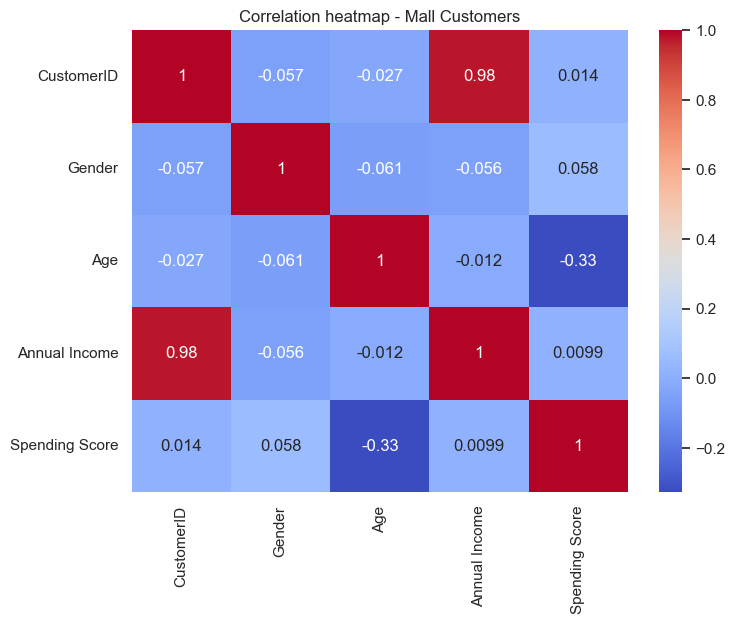

In [38]:
df_heatmap = df.copy()
df_heatmap['Gender'] = df_heatmap['Gender'].map({'Male': 0, 'Female': 1})

plt.figure(figsize=(8, 6))
sns.heatmap(df_heatmap.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation heatmap - Mall Customers')
plt.show()

#### Question 2: Do you notice any strange or unexpected relation? Can you think of why this is? Is it pure chance or is there more going on?

In [39]:
print('Strongest relation with Spending Score in the heatmap:')
print(df_heatmap.corr(numeric_only=True)['Spending Score'].sort_values(ascending=False))

Strongest relation with Spending Score in the heatmap:
Spending Score    1.000000
Gender            0.058109
CustomerID        0.013835
Annual Income     0.009903
Age              -0.327227
Name: Spending Score, dtype: float64


De meest opvallende relatie met de **Spending Score** is de **negatieve correlatie met Age**.

Dit betekent dat jongere klanten gemiddeld een hogere uitgavenscore hebben, terwijl oudere klanten gemiddeld lager scoren op deze maatstaf. Dit is geen toeval, maar waarschijnlijk een echt gedragspatroon binnen deze dataset.

De bijna perfecte correlatie tussen **CustomerID** en **Annual Income** is daarentegen wel verdacht. CustomerID is gewoon een volgnummer en zou inhoudelijk niets moeten verklaren. Die correlatie is daarom een artefact van de manier waarop de gegevens zijn georganiseerd of opgeslagen.

## 7.4 Model Evaluation

#### Question 3: We will be trying to visualize our data. Since a simple to understand 2D plot can only support two variables (a dependant and an independant one) we are forced to limit our model to two variables. Our dependant variable will be Spending Score as that is what we are trying to visualize. Pick an independant variable and figure out the best value for k.

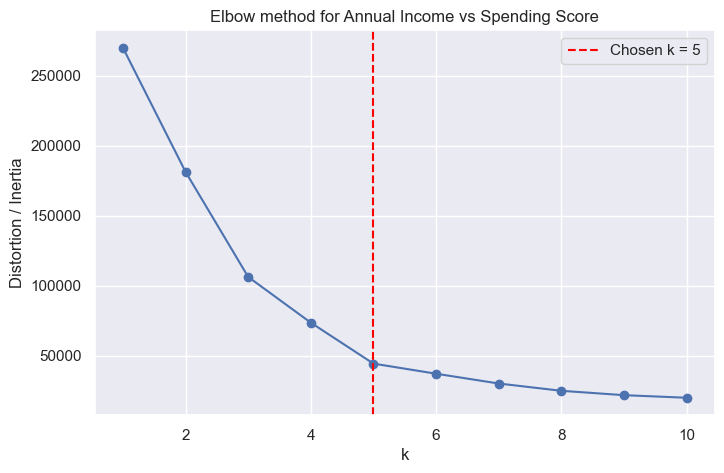

Chosen columns: Annual Income and Spending Score
Best value for k (based on the elbow): 5


In [40]:
def find_elbow_k(distortions, k_values):
    x1, y1 = k_values[0], distortions[0]
    x2, y2 = k_values[-1], distortions[-1]

    distances = []
    for x0, y0 in zip(k_values, distortions):
        numerator = abs((y2 - y1) * x0 - (x2 - x1) * y0 + x2 * y1 - y2 * x1)
        denominator = math.sqrt((y2 - y1) ** 2 + (x2 - x1) ** 2)
        distances.append(numerator / denominator)

    return k_values[int(np.argmax(distances))]

x_col = 'Annual Income'
y_col = 'Spending Score'
X = df[[x_col, y_col]].values

k_values = list(range(1, 11))
distortions = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    distortions.append(model.inertia_)

best_k = find_elbow_k(distortions, k_values)

plt.figure(figsize=(8, 5))
plt.plot(k_values, distortions, marker='o')
plt.axvline(best_k, color='red', linestyle='--', label=f'Chosen k = {best_k}')
plt.xlabel('k')
plt.ylabel('Distortion / Inertia')
plt.title(f'Elbow method for {x_col} vs {y_col}')
plt.legend()
plt.show()

print(f'Chosen columns: {x_col} and {y_col}')
print(f'Best value for k (based on the elbow): {best_k}')

#### Question 4: Plot a graph showing the Spending Score in function of the column you picked. Make sure you can visualize each individual cluster and its centroids.

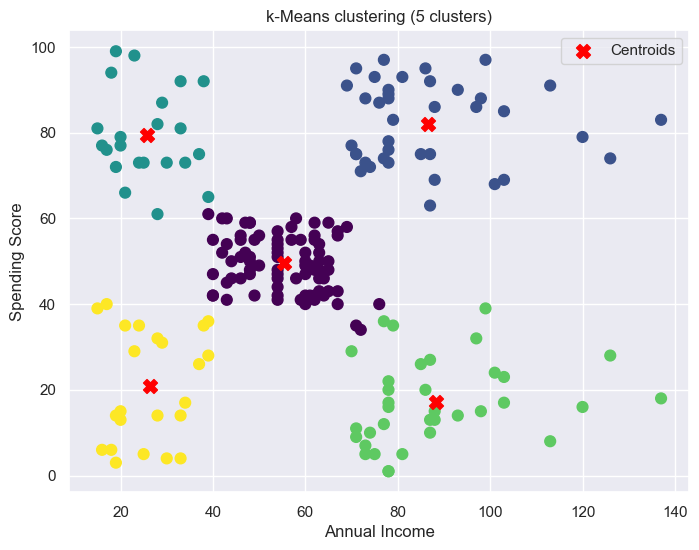

In [41]:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X)
centroids = kmeans.cluster_centers_

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=clusters, s=60, cmap='viridis')
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=100, marker='X', label='Centroids')
plt.xlabel(x_col)
plt.ylabel(y_col)
plt.title(f'k-Means clustering ({best_k} clusters)')
plt.legend()
plt.show()

#### Question 5: You've explored the relation of one column with Spending Score, now explore all other columns. Are there any more insights to be revealed?

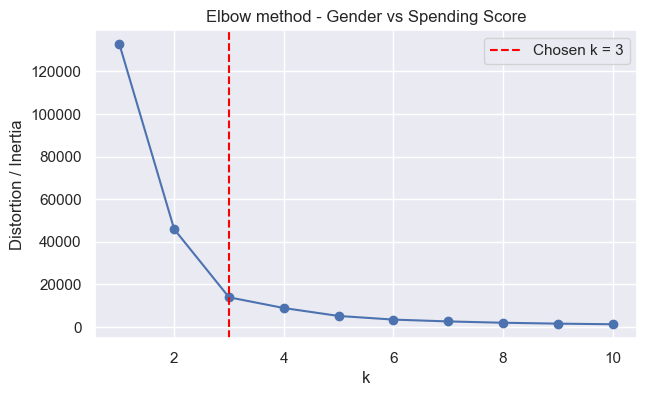

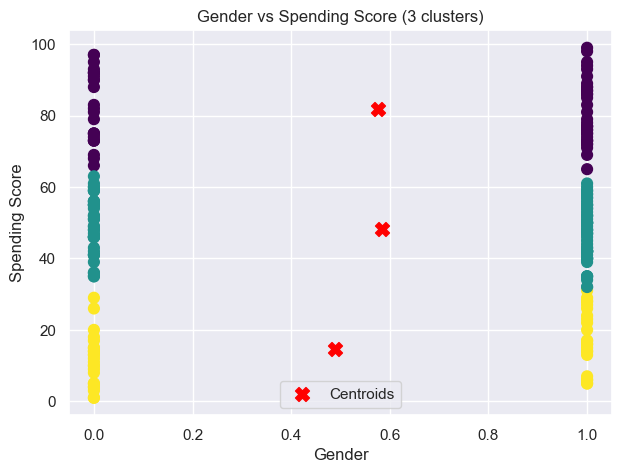

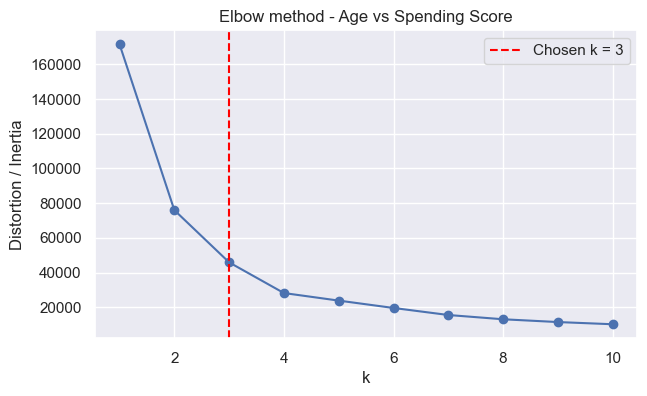

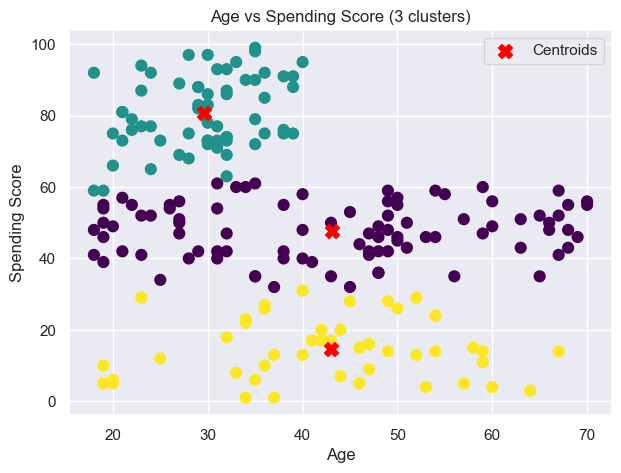

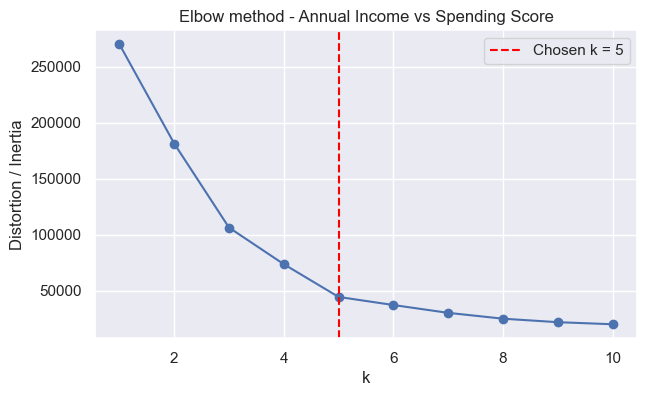

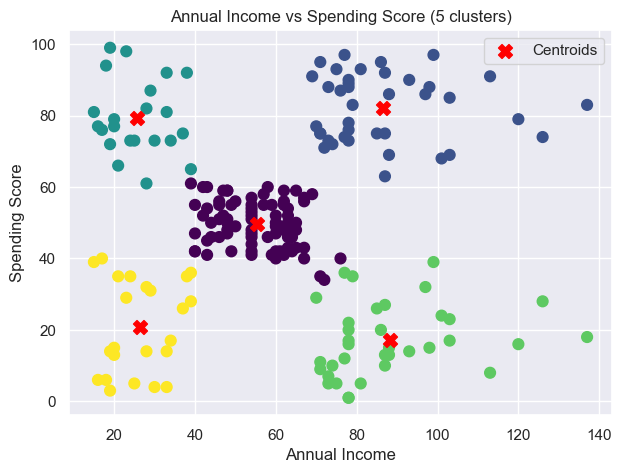

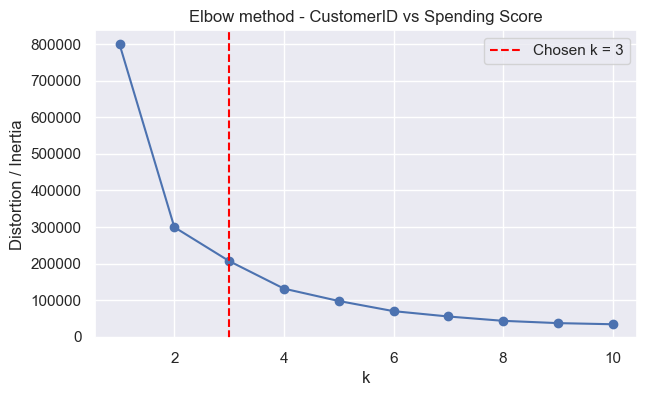

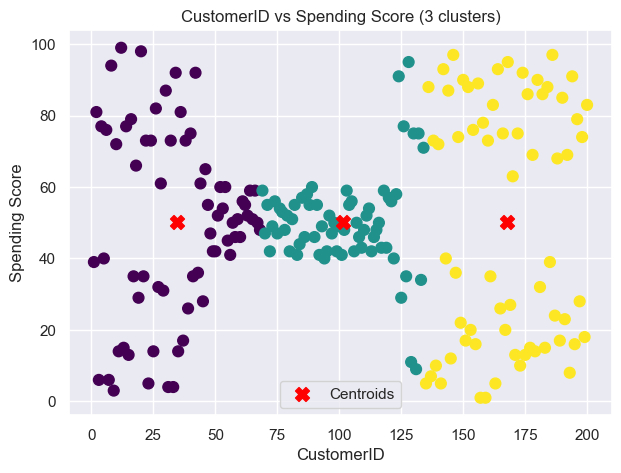

Chosen k-values: {'Gender': 3, 'Age': 3, 'Annual Income': 5, 'CustomerID': 3}


In [42]:
df_explore = df.copy()
df_explore['Gender'] = df_explore['Gender'].map({'Male': 0, 'Female': 1})

candidate_columns = ['Gender', 'Age', 'Annual Income', 'CustomerID']
best_k_per_column = {}

for col in candidate_columns:
    X_col = df_explore[[col, 'Spending Score']].values

    distortions = []
    k_values = list(range(1, 11))
    for k in k_values:
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        model.fit(X_col)
        distortions.append(model.inertia_)

    chosen_k = find_elbow_k(distortions, k_values)
    best_k_per_column[col] = chosen_k

    plt.figure(figsize=(7, 4))
    plt.plot(k_values, distortions, marker='o')
    plt.axvline(chosen_k, color='red', linestyle='--', label=f'Chosen k = {chosen_k}')
    plt.xlabel('k')
    plt.ylabel('Distortion / Inertia')
    plt.title(f'Elbow method - {col} vs Spending Score')
    plt.legend()
    plt.show()

    kmeans_col = KMeans(n_clusters=chosen_k, random_state=42, n_init=10)
    labels_col = kmeans_col.fit_predict(X_col)
    centroids_col = kmeans_col.cluster_centers_

    plt.figure(figsize=(7, 5))
    plt.scatter(X_col[:, 0], X_col[:, 1], c=labels_col, s=60, cmap='viridis')
    plt.scatter(centroids_col[:, 0], centroids_col[:, 1], c='red', s=100, marker='X', label='Centroids')
    plt.xlabel(col)
    plt.ylabel('Spending Score')
    plt.title(f'{col} vs Spending Score ({chosen_k} clusters)')
    plt.legend()
    plt.show()

print('Chosen k-values:', best_k_per_column)

Inzichten:
- De verhouding tussen jaarinkomen en uitgaven biedt de duidelijkste en meest bruikbare segmentatie.
- De verhouding tussen leeftijd en uitgaven laat wel enige structuur zien, maar de groepen overlappen elkaar meer.
- De verhouding tussen geslacht en uitgaven is veel minder informatief en verdeelt de gegevens grotendeels in twee verticale banden.
- Het klant-ID mag nooit als echte variabele worden gebruikt: elke structuur die hierin te zien is, is kunstmatig, omdat het slechts een identificatiecode is.

#### Question 6: Based on this, does our preferred value in the correlation matrix for picking columns still hold up? What would you change?

Niet volledig.

Een correlatiematrix is nuttig als eerste verkenning, maar voor clustering is de beste variabelecombinatie niet noodzakelijk degene met de sterkste lineaire correlatie. In de heatmap leek **Age** inhoudelijk het meest opvallend tegenover **Spending Score**, maar de clusterplots tonen dat **Annual Income + Spending Score** veel duidelijkere segmenten oplevert.

Conclusie: de heatmap blijft nuttig als verkenning, maar voor deze dataset zijn **Annual Income** en **Spending Score** nog steeds de beste keuze voor visualisatie en segmentatie. **CustomerID** mag daarbij niet gebruikt worden, omdat het enkel een identificatiekolom is.

## 7.5 Questions

#### Question 1: See section 7.3
#### Question 2: See section 7.3
#### Question 3: See section 7.4
#### Question 4: See section 7.4
#### Question 5: See section 7.4
#### Question 6: See section 7.4
#### Question 7: Revisit the old wine dataset. Copy it to your current folder and import it. Drop the Id column just like we did in the notebook on decision trees.

In [43]:
wine = pd.read_csv('Wine.csv')

if 'Id' in wine.columns:
    wine = wine.drop('Id', axis=1)

wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


#### Question 8: We want to explore the vizualization of quality as the dependant variable and all other variables. Calculate the best value of k for each graph (11 in total) and plot them. What can you learn from this?

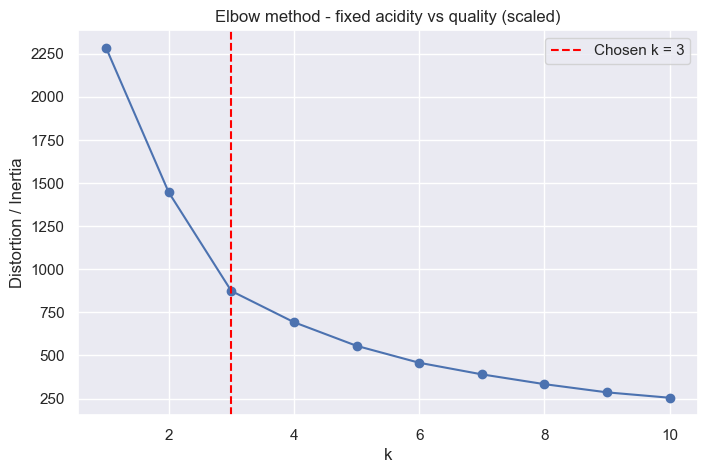

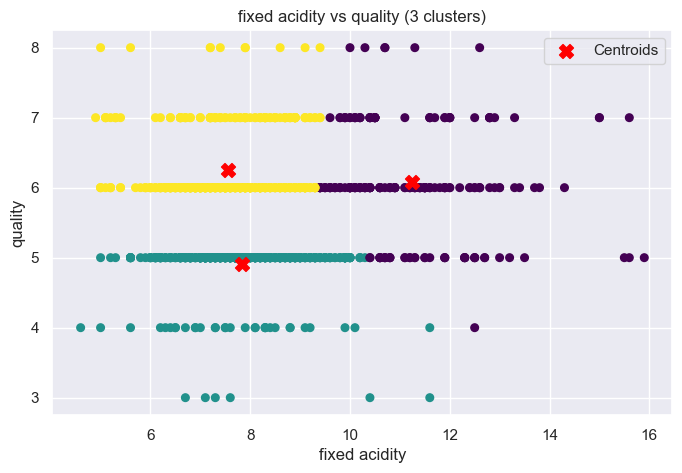

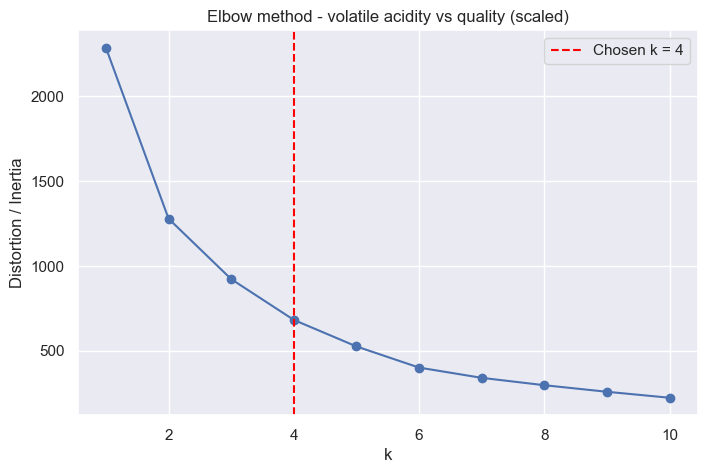

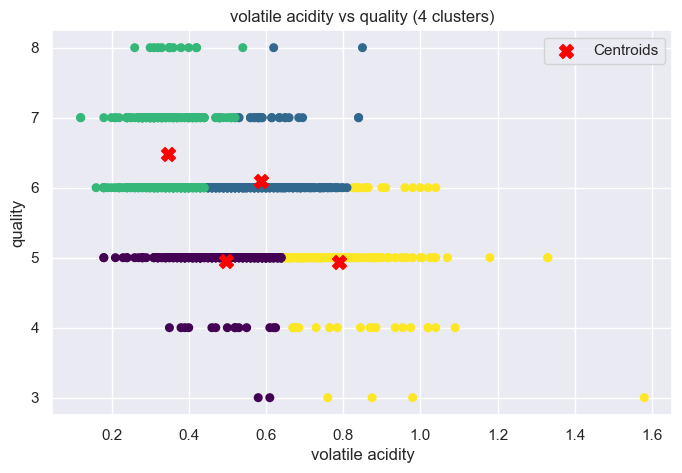

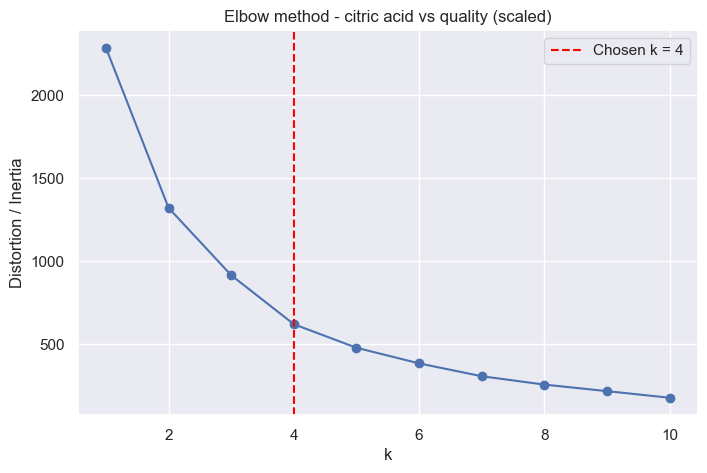

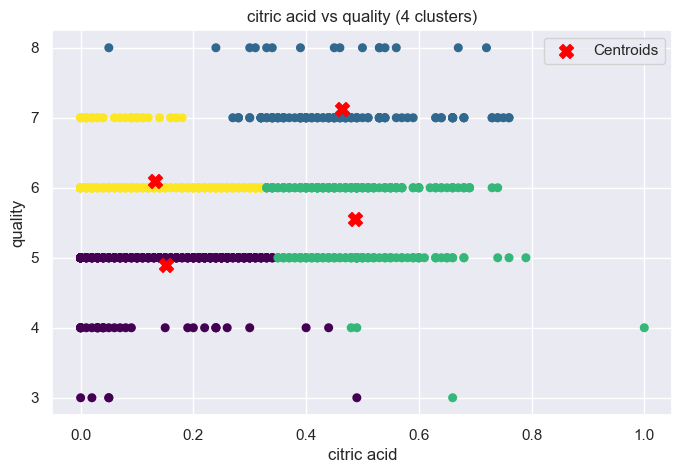

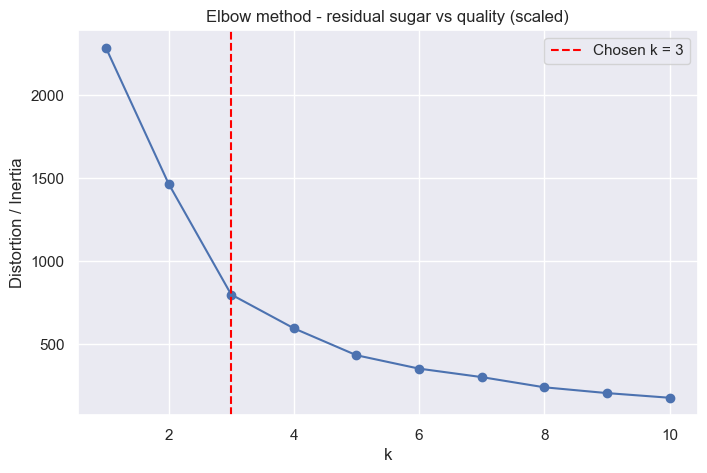

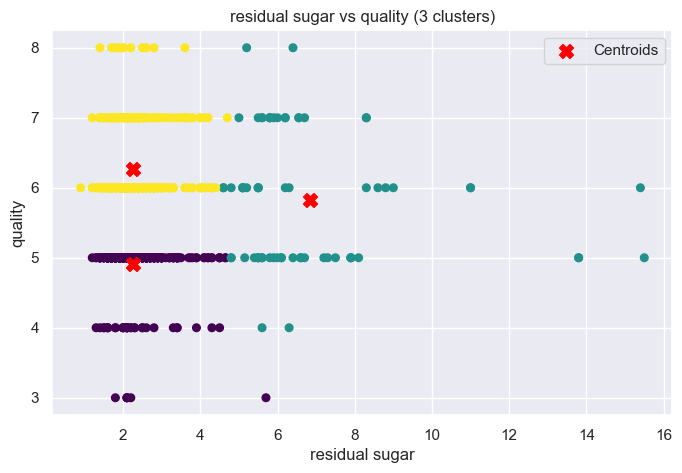

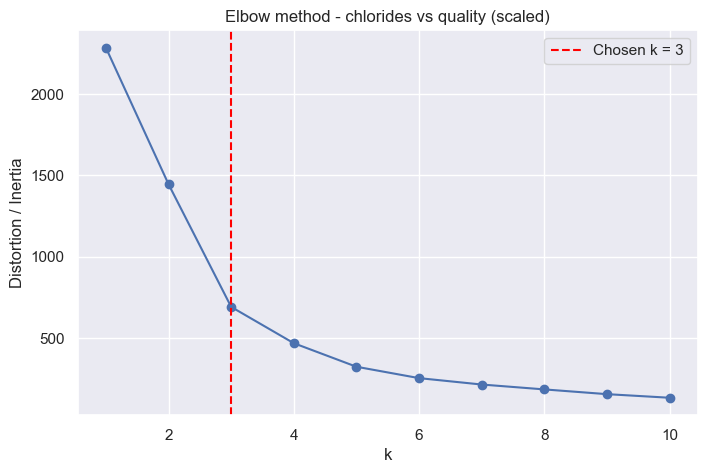

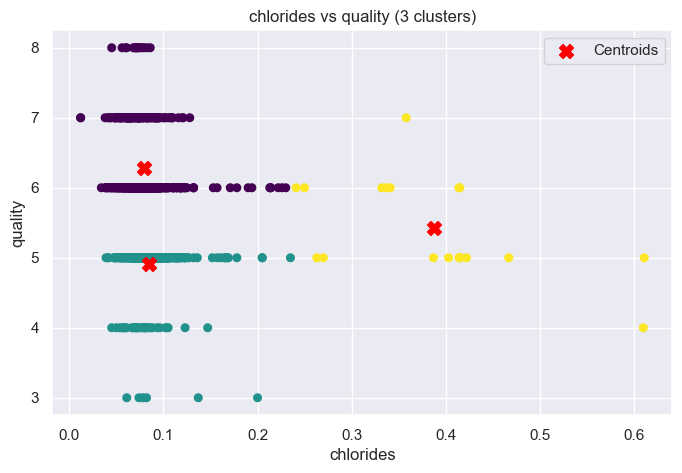

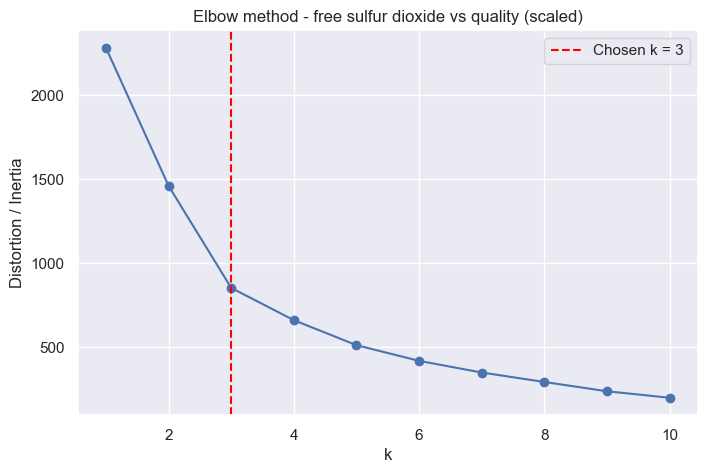

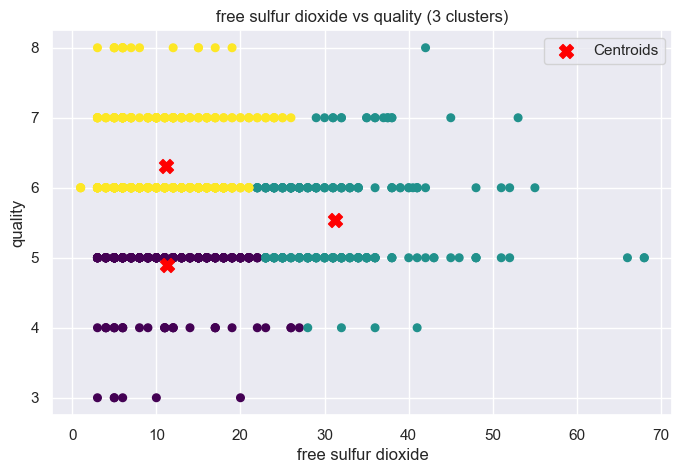

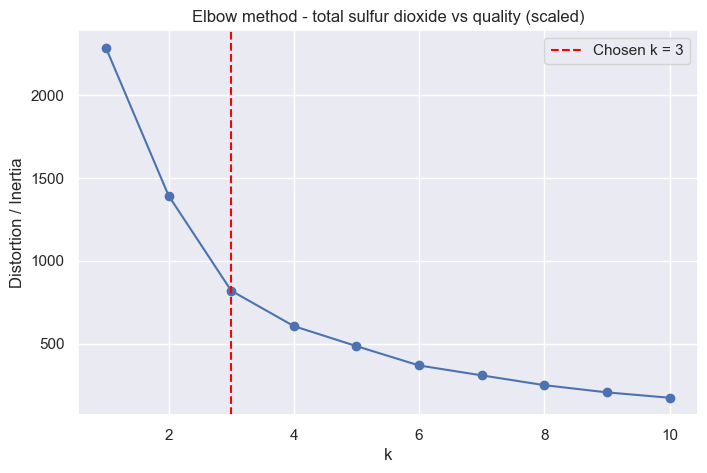

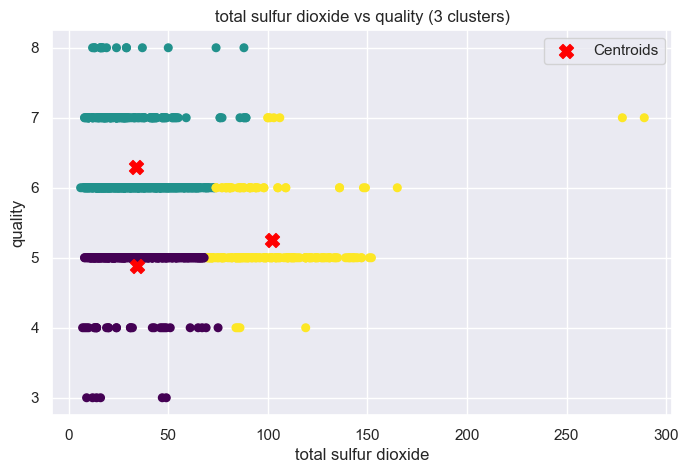

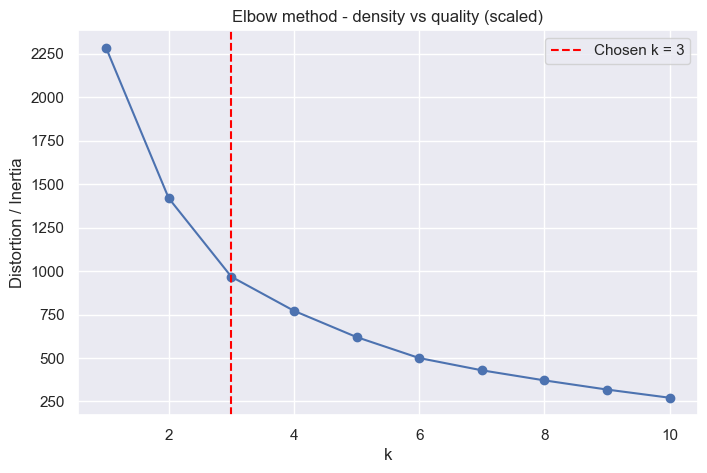

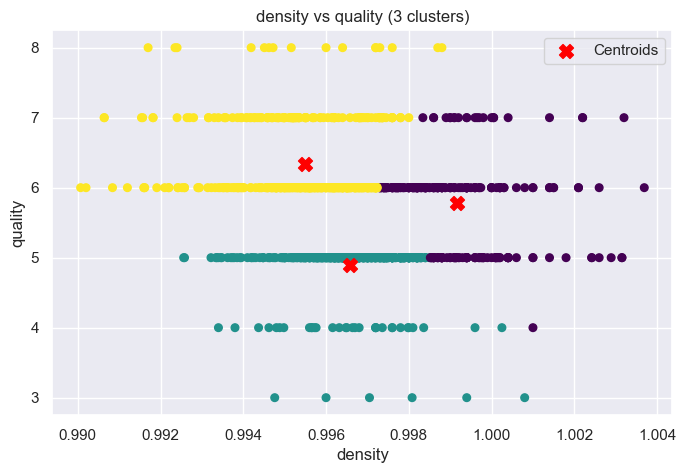

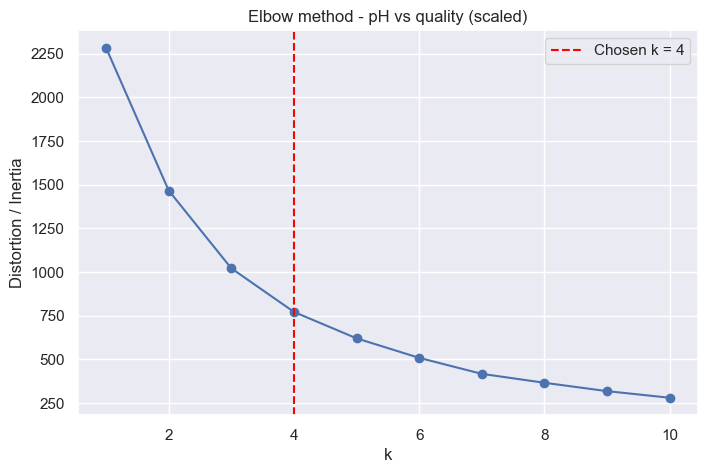

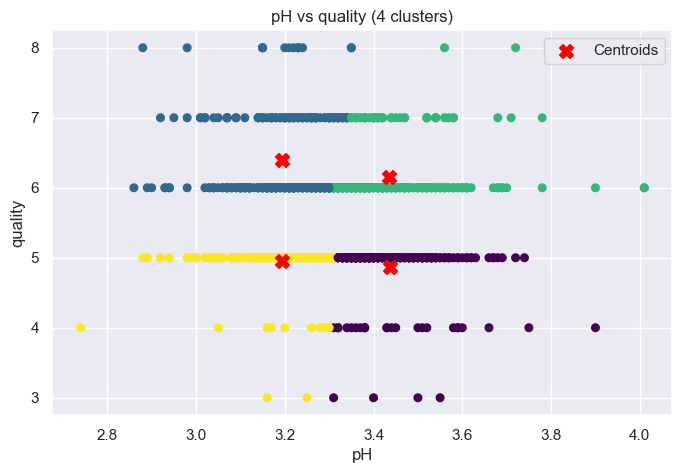

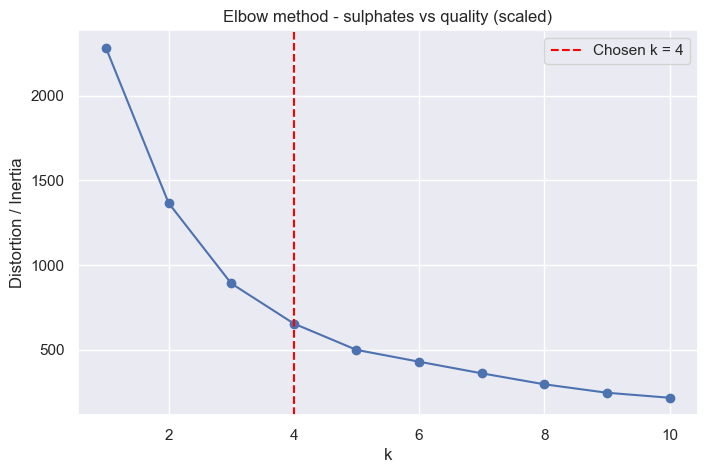

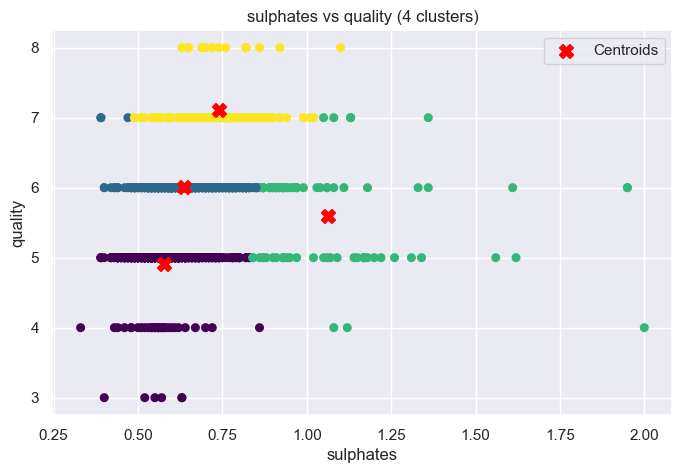

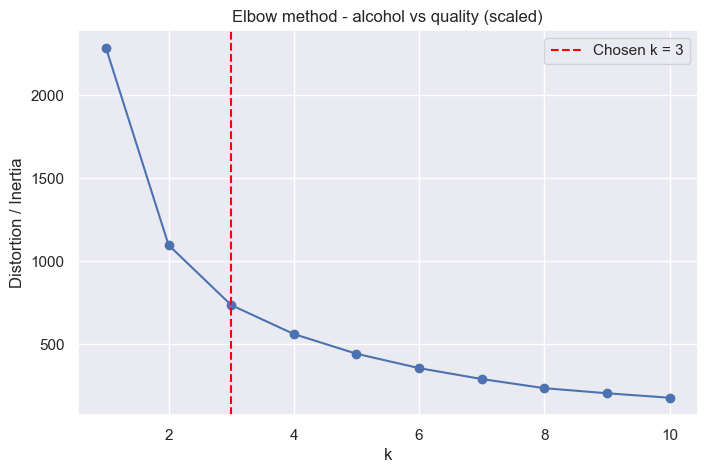

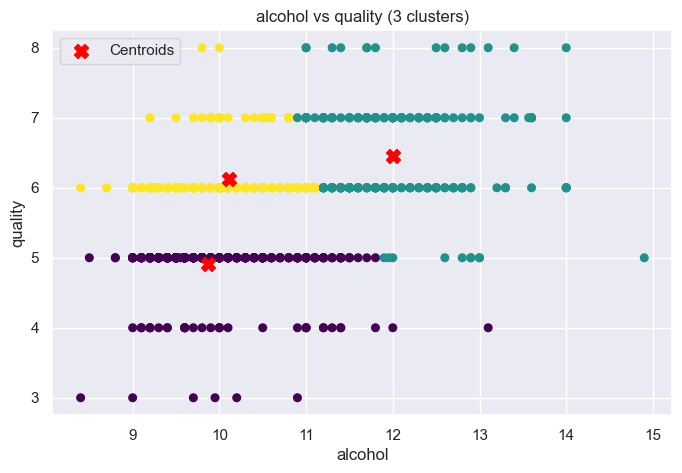

Chosen k per feature:
{'fixed acidity': 3, 'volatile acidity': 4, 'citric acid': 4, 'residual sugar': 3, 'chlorides': 3, 'free sulfur dioxide': 3, 'total sulfur dioxide': 3, 'density': 3, 'pH': 4, 'sulphates': 4, 'alcohol': 3}


In [44]:
target_col = 'quality'
feature_columns = [col for col in wine.columns if col != target_col]

best_k_wine = {}

for feature in feature_columns:
    X_feature = wine[[feature, target_col]].dropna().values

    scaler_feature = StandardScaler()
    X_feature_scaled = scaler_feature.fit_transform(X_feature)

    distortions = []
    k_values = list(range(1, 11))
    for k in k_values:
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        model.fit(X_feature_scaled)
        distortions.append(model.inertia_)

    chosen_k = find_elbow_k(distortions, k_values)
    best_k_wine[feature] = chosen_k

    plt.figure(figsize=(8, 5))
    plt.plot(k_values, distortions, marker='o')
    plt.axvline(chosen_k, color='red', linestyle='--', label=f'Chosen k = {chosen_k}')
    plt.xlabel('k')
    plt.ylabel('Distortion / Inertia')
    plt.title(f'Elbow method - {feature} vs {target_col} (scaled)')
    plt.legend()
    plt.show()

    kmeans_feature = KMeans(n_clusters=chosen_k, random_state=42, n_init=10)
    labels_feature = kmeans_feature.fit_predict(X_feature_scaled)
    centroids_feature_scaled = kmeans_feature.cluster_centers_
    centroids_feature = scaler_feature.inverse_transform(centroids_feature_scaled)

    plt.figure(figsize=(8, 5))
    plt.scatter(X_feature[:, 0], X_feature[:, 1], c=labels_feature, s=30, cmap='viridis')
    plt.scatter(centroids_feature[:, 0], centroids_feature[:, 1], c='red', s=100, marker='X', label='Centroids')
    plt.xlabel(feature)
    plt.ylabel(target_col)
    plt.title(f'{feature} vs {target_col} ({chosen_k} clusters)')
    plt.legend()
    plt.show()

print('Chosen k per feature:')
print(best_k_wine)

Wat leer je hier meestal uit?
- Sommige features tonen wat meer structuur tegenover quality, maar veel grafieken overlappen sterk.
- Dat betekent dat individuele features quality niet netjes opsplitsen in duidelijke groepen.
- Met andere woorden: er is meestal geen sterke natuurlijke clusterstructuur per kwaliteitsniveau.
- Dat is meteen een waarschuwing dat clustering waarschijnlijk geen sterke predictor voor quality zal zijn.
- Omdat k-means afstandsgebaseerd is, schalen we eerst de variabelen zodat features met grotere schaal het resultaat niet domineren.

#### Question 9: Try and use clustering as a way to predict your quality. Feel free to use all columns for this model. Think of how many clusters you would expect in this case!

In [45]:
n_clusters = wine['quality'].nunique()

X_wine = wine.drop('quality', axis=1)
y_wine = wine['quality']

scaler_wine = StandardScaler()
X_wine_scaled = scaler_wine.fit_transform(X_wine)

kmeans_wine = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
cluster_labels = kmeans_wine.fit_predict(X_wine_scaled)

cluster_to_quality = {}
for cluster_id in np.unique(cluster_labels):
    cluster_quality_values = y_wine[cluster_labels == cluster_id]
    most_common_quality = mode(cluster_quality_values, keepdims=False).mode
    cluster_to_quality[cluster_id] = most_common_quality

predicted_quality = np.array([cluster_to_quality[label] for label in cluster_labels])

results = wine.copy()
results['cluster'] = cluster_labels
results['predicted_quality'] = predicted_quality

print('Cluster to quality mapping:')
print(cluster_to_quality)
print()
results[['quality', 'cluster', 'predicted_quality']].head(10)

Cluster to quality mapping:
{np.int32(0): np.int64(5), np.int32(1): np.int64(5), np.int32(2): np.int64(5), np.int32(3): np.int64(6), np.int32(4): np.int64(6), np.int32(5): np.int64(6)}



,quality,cluster,predicted_quality
0,5,0,5
1,5,0,5
2,5,0,5
3,6,5,6
4,5,0,5
5,5,0,5
6,5,0,5
7,7,0,5
8,7,0,5
9,5,0,5


#### Question 10: Evaluate the model. Is it any good for this kind of prediction? Why is this? Are there any noteable differences when seen against predicting the digits dataset? What makes a dataset 'good' to use with clustering for predicting a value? Elaborate based on your findings from question 8 and 9.

Accuracy: 0.5464

Confusion matrix:


Predicted quality,5,6
Actual quality,,
3,4,2
4,22,11
5,383,99
6,221,241
7,24,119
8,0,16


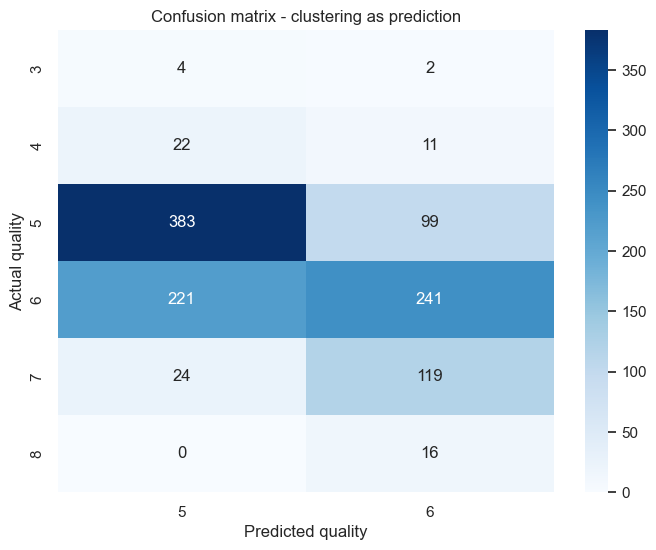

In [46]:
accuracy = accuracy_score(results['quality'], results['predicted_quality'])

confusion = pd.crosstab(
    results['quality'],
    results['predicted_quality'],
    rownames=['Actual quality'],
    colnames=['Predicted quality']
)

print(f'Accuracy: {accuracy:.4f}')
print()
print('Confusion matrix:')
display(confusion)

plt.figure(figsize=(8, 6))
sns.heatmap(confusion, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion matrix - clustering as prediction')
plt.show()

Interpretatie:
- Dit model presteert slechts matig voor wine quality prediction.
- De reden is dat k-means **ongesuperviseerd** is: het probeert natuurlijke groepen te vinden en leert niet rechtstreeks uit de kwaliteitslabels.
- Bij deze dataset overlappen verschillende kwaliteitsklassen sterk in de feature space, waardoor clusters geen nette scheiding per quality vormen.
- We hebben de features eerst geschaald met **StandardScaler**, want k-means is afstandsgebaseerd en anders zouden variabelen met een grotere schaal het model te sterk beïnvloeden.
- Dat is anders dan bij bijvoorbeeld digits, waar klassen vaak veel duidelijker natuurlijke groepen vormen.
- Een dataset is geschikter voor clustering-as-prediction wanneer:
  * de klassen echt natuurlijke groepen vormen,
  * de overlap tussen klassen klein is,
  * en meerdere features samen duidelijke clusterstructuren tonen.